# =========================================================
# 2) INDICATORS
# Strategy requires:
#   - Volatility signal: ATR(199) increasing:
#       ATR199(shift=4) > ATR199(shift=3)
#   - Entry:
#       BuyStop  = Highest(HIGH, 30, shift=1) + 2.2 * round(ATR14(shift=1))
#       SellStop = Lowest (LOW,  30, shift=1) - 2.2 * round(ATR14(shift=1))
#     Pending expiration = 7 bars
#   - SL/TP:
#       SL_dist = 2.3 * ATR20(shift=1)
#       TP_dist = 2.5 * ATR20(shift=1)
#   - No trailing, no time exit
#   - NOTE: code quirk:
#       ShortEntrySignal = LongEntrySignal AND NOT LongEntrySignal => effectively short NEVER triggers.
#       We'll replicate that behavior by default (short disabled).
# =========================================================

⏳ Downloading ETHUSDT 1h...
✅ Data ready: 53122 bars after indicator warmup.
🚀 Running backtest...

🎯 ATR199 Rising Vol Breakout (H1) (short disabled by code quirk)
  Final Equity: 15627.166368
  Total Return: 0.562717
 CAGR (approx): 0.076428
  Max Drawdown: -0.164646
        Sharpe: 0.859608
        Trades: 379
       Winrate: 0.538259
 Profit Factor: 1.252872


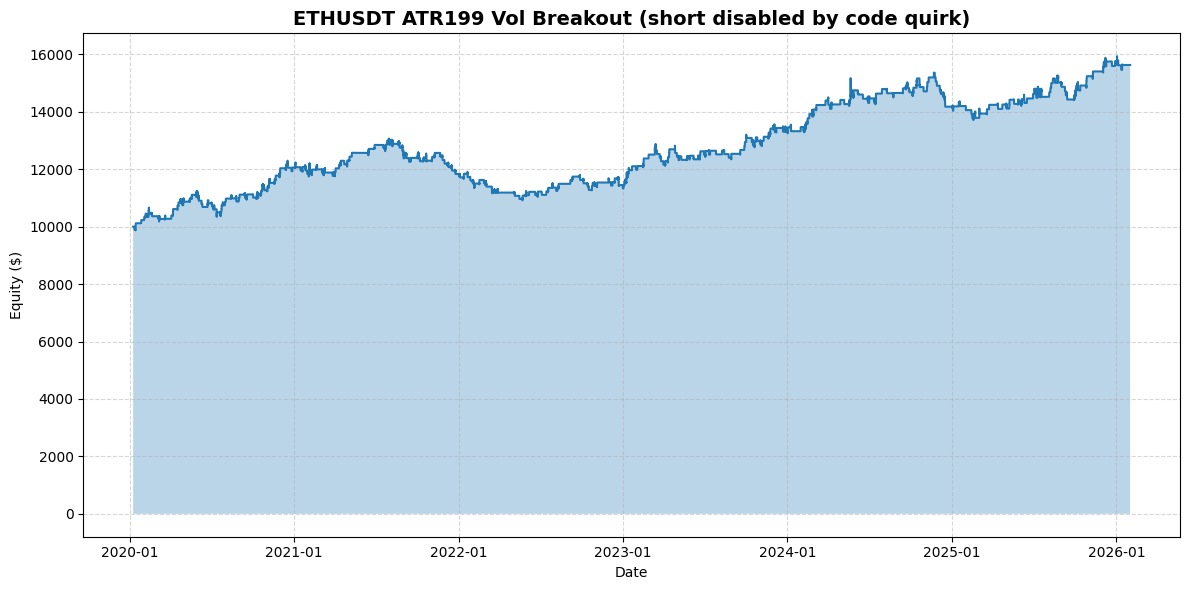


📊 Trades (first 12):
          Exit Time Type  Entry       Exit   Qty         PnL      Reason      Balance
2020-01-11 21:00:00 LONG 147.53 144.338614 31.33  -99.986137   Stop Loss  9900.013863
2020-01-14 12:00:00 LONG 149.20 151.935353 39.34  107.608773 Take Profit 10007.622636
2020-01-14 16:00:00 LONG 155.53 158.915924 32.12  108.755882 Take Profit 10116.378519
2020-01-27 00:00:00 LONG 165.83 169.273311 31.93  109.944934 Take Profit 10226.323453
2020-02-02 12:00:00 LONG 188.68 192.850541 26.65  111.144916 Take Profit 10337.468368
2020-02-05 16:00:00 LONG 196.00 200.198605 26.76  112.354668 Take Profit 10449.823036
2020-02-06 13:00:00 LONG 214.76 209.247233 18.95 -104.466928   Stop Loss 10345.356109
2020-02-11 17:00:00 LONG 229.52 235.442207 18.98  112.403481 Take Profit 10457.759590
2020-02-12 07:00:00 LONG 247.07 254.023034 16.34  113.612575 Take Profit 10571.372165
2020-02-13 08:00:00 LONG 266.79 258.560151 12.84 -105.671257   Stop Loss 10465.700908
2020-02-19 20:00:00 LONG 282.63 

In [1]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://api.binance.com/"
    url = base_url + "api/v3/klines"

    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")

    while start_time < end_time:
        params = {
            "symbol": symbol.upper(),
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Fetch error:", r.status_code, r.text)
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)

        except Exception as e:
            print("Fetch exception:", e)
            break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# Strategy requires:
#   - Volatility signal: ATR(199) increasing:
#       ATR199(shift=4) > ATR199(shift=3)
#   - Entry:
#       BuyStop  = Highest(HIGH, 30, shift=1) + 2.2 * round(ATR14(shift=1))
#       SellStop = Lowest (LOW,  30, shift=1) - 2.2 * round(ATR14(shift=1))
#     Pending expiration = 7 bars
#   - SL/TP:
#       SL_dist = 2.3 * ATR20(shift=1)
#       TP_dist = 2.5 * ATR20(shift=1)
#   - No trailing, no time exit
#   - NOTE: code quirk:
#       ShortEntrySignal = LongEntrySignal AND NOT LongEntrySignal => effectively short NEVER triggers.
#       We'll replicate that behavior by default (short disabled).
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    # True Range
    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    # Wilder ATR (RMA)
    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_14"] = calc_atr(data["TR"], 14)
    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_199"] = calc_atr(data["TR"], 199)

    # Highest(HIGH, 30) and Lowest(LOW, 30) for entry base
    data["HH_30_High"] = data["High"].rolling(window=30).max()
    data["LL_30_Low"] = data["Low"].rolling(window=30).min()

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER
# Signal at bar t:
#   LongEntrySignal TRUE if ATR199(shift=4) > ATR199(shift=3)
#   ShortEntrySignal is set equal to LongEntrySignal in code,
#   BUT execution requires ShortEntrySignal AND NOT LongEntrySignal -> never true.
#
# So by default: only places BUY_STOP orders when signal holds.
#
# Pending:
#   BUY_STOP triggers if High(t) >= entry_price.
# Exit:
#   SL/TP checked on each bar using Low/High.
# =========================================================
class ATR199_VolBreakout_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0, emulate_short_bug: bool = True):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        # Position
        self.position = None  # "LONG" / "SHORT" / None
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0
        self.qty = 0.0

        # Pending stop order
        self.pending_order = None

        # Params
        self.lookback = 30
        self.price_entry_mult = 2.2
        self.sl_coef = 2.3
        self.tp_coef = 2.5
        self.pending_expiration = 7

        # Money management
        self.risk_pct = 0.01
        self.mm_max_lots = 100.0
        self.mm_decimals = 2

        # Behavior
        self.emulate_short_bug = emulate_short_bug

    @staticmethod
    def round_value(x: float) -> float:
        # StrategyQuant/JForex "roundValue" depends on instrument pip scale.
        # Here we emulate simplest rounding to nearest integer (common stand-in).
        # If you know tickSize, you can replace by: round(x / tickSize) * tickSize
        return float(np.round(x))

    def run(self):
        idxs = self.df.index

        for i in range(len(self.df)):
            t = idxs[i]
            bar = self.df.iloc[i]

            # A) Manage open position (SL/TP only)
            if self.position is not None:
                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["High"] >= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue
                else:  # SHORT
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t)
                        continue
                    if bar["Low"] <= self.tp:
                        self.close_position(self.tp, t, "Take Profit")
                        self.append_equity(t)
                        continue

            # B) Manage pending (expiration / fill)
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]
                    if self.pending_order["type"] == "BUY_STOP":
                        if bar["High"] >= p:
                            fill = max(p, bar["Open"])  # conservative
                            self.open_position("LONG", fill, i,
                                               self.pending_order["sl_dist"],
                                               self.pending_order["tp_dist"])
                            self.pending_order = None
                    elif self.pending_order["type"] == "SELL_STOP":
                        if bar["Low"] <= p:
                            fill = min(p, bar["Open"])  # conservative
                            self.open_position("SHORT", fill, i,
                                               self.pending_order["sl_dist"],
                                               self.pending_order["tp_dist"])
                            self.pending_order = None

            # C) If flat & no pending -> compute signal & place pending
            # Needs ATR199 shift=4 and shift=3 => i-4, i-3
            # Entry bases HH/LL shift=1 => i-1
            # ATR14 shift=1 => i-1
            # SL/TP ATR20 shift=1 => i-1
            if self.position is None and self.pending_order is None:
                if i < 4:
                    self.append_equity(t)
                    continue

                atr199_4 = self.df.iloc[i-4]["ATR_199"]
                atr199_3 = self.df.iloc[i-3]["ATR_199"]

                long_signal = (atr199_4 > atr199_3)
                short_signal = long_signal  # code sets ShortEntrySignal = LongEntrySignal

                # Execution quirk:
                # short branch only runs when short_signal AND NOT long_signal.
                if self.emulate_short_bug:
                    short_allowed = short_signal and (not long_signal)  # always False
                else:
                    short_allowed = short_signal  # if you want symmetrical long/short

                if not long_signal and not short_allowed:
                    self.append_equity(t)
                    continue

                hh_30_1 = self.df.iloc[i-1]["HH_30_High"]
                ll_30_1 = self.df.iloc[i-1]["LL_30_Low"]

                atr14_1 = self.df.iloc[i-1]["ATR_14"]
                atr14_rounded = self.round_value(atr14_1)

                atr20_1 = self.df.iloc[i-1]["ATR_20"]
                sl_dist = self.sl_coef * atr20_1
                tp_dist = self.tp_coef * atr20_1

                if long_signal:
                    entry = hh_30_1 + self.price_entry_mult * atr14_rounded
                    self.pending_order = {
                        "type": "BUY_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }
                elif short_allowed:
                    entry = ll_30_1 - self.price_entry_mult * atr14_rounded
                    self.pending_order = {
                        "type": "SELL_STOP",
                        "price": float(entry),
                        "sl_dist": float(sl_dist),
                        "tp_dist": float(tp_dist),
                        "expire_idx": i + self.pending_expiration
                    }

            self.append_equity(t)

    def append_equity(self, t):
        close_px = self.df.loc[t, "Close"]
        mtm = self.balance
        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty
        self.equity_curve.append({"time": t, "equity": mtm})

    def open_position(self, pos_type: str, price: float, bar_idx: int, sl_dist: float, tp_dist: float):
        self.position = pos_type
        self.entry_price = float(price)

        if pos_type == "LONG":
            self.sl = self.entry_price - sl_dist
            self.tp = self.entry_price + tp_dist
        else:
            self.sl = self.entry_price + sl_dist
            self.tp = self.entry_price - tp_dist

        # Risk fixed % of balance sizing
        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        qty = min(qty, self.mm_max_lots)
        qty = np.floor(qty * (10 ** self.mm_decimals)) / (10 ** self.mm_decimals)
        self.qty = float(qty)

    def close_position(self, price: float, t, reason: str):
        price = float(price)
        if self.position == "LONG":
            pnl = (price - self.entry_price) * self.qty
        else:
            pnl = (self.entry_price - price) * self.qty

        self.balance += pnl

        self.trades.append({
            "Exit Time": t,
            "Type": self.position,
            "Entry": self.entry_price,
            "Exit": price,
            "Qty": self.qty,
            "PnL": pnl,
            "Reason": reason,
            "Balance": self.balance
        })

        self.position = None
        self.qty = 0.0
        self.entry_price = 0.0
        self.sl = 0.0
        self.tp = 0.0


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data)
    eq_df.set_index("time", inplace=True)
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = float(eq_df["equity"].iloc[-1])
    total_return = (final_equity - initial_balance) / initial_balance

    days = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 0.0
    cagr = ((final_equity / initial_balance) ** (1/years) - 1) if years > 0 else 0.0

    running_max = eq_df["equity"].cummax()
    dd = (eq_df["equity"] - running_max) / running_max
    max_dd = float(dd.min())

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret = eq_df["returns"].std()

    bars_per_year = (len(eq_df) / years) if years > 0 else 8760
    sharpe = (mean_ret / std_ret) * np.sqrt(bars_per_year) if std_ret and std_ret != 0 else 0.0

    total_trades = len(trades_df)
    win_trades = int((trades_df["PnL"] > 0).sum()) if total_trades > 0 else 0
    win_rate = win_trades / total_trades if total_trades > 0 else 0.0

    gross_profit = float(trades_df.loc[trades_df["PnL"] > 0, "PnL"].sum()) if total_trades > 0 else 0.0
    gross_loss = float(abs(trades_df.loc[trades_df["PnL"] < 0, "PnL"].sum())) if total_trades > 0 else 0.0
    profit_factor = (gross_profit / gross_loss) if gross_loss > 0 else 0.0

    return {
        "Final Equity": final_equity,
        "Total Return": float(total_return),
        "CAGR (approx)": float(cagr),
        "Max Drawdown": max_dd,
        "Sharpe": float(sharpe),
        "Trades": int(total_trades),
        "Winrate": float(win_rate),
        "Profit Factor": float(profit_factor),
        "equity_df": eq_df
    }

def print_report_and_plot(metrics, symbol: str, title_suffix: str = ""):
    print("\n" + "=" * 92)
    print(f"🎯 ATR199 Rising Vol Breakout (H1) {title_suffix}".strip())
    print("=" * 92)
    for k in ["Final Equity", "Total Return", "CAGR (approx)", "Max Drawdown", "Sharpe", "Trades", "Winrate", "Profit Factor"]:
        v = metrics[k]
        if isinstance(v, float):
            print(f"{k:>14}: {v:.6f}")
        else:
            print(f"{k:>14}: {v}")
    print("=" * 92)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} ATR199 Vol Breakout {title_suffix}".strip(), fontsize=14, fontweight="bold")
    plt.xlabel("Date")
    plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    symbol = "ETHUSDT"
    interval = "1h"

    # Change as needed
    start_date = "01/01/2020"
    end_date = "31/01/2026"

    df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
    if df_raw.empty or len(df_raw) < 500:
        print("❌ Not enough data / download failed.")
        raise SystemExit

    df = calculate_indicators(df_raw)
    print(f"✅ Data ready: {len(df)} bars after indicator warmup.")

    # emulate_short_bug=True -> replicate your described SQX code (short effectively never triggers)
    bt = ATR199_VolBreakout_Backtester(df, initial_balance=10000.0, emulate_short_bug=True)

    print("🚀 Running backtest...")
    bt.run()

    trades_df = pd.DataFrame(bt.trades)
    if trades_df.empty:
        print("⚠️ No trades generated (likely because ATR199 rising is rare + stop orders not filled).")
        raise SystemExit

    metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
    title_suffix = "(short disabled by code quirk)" if bt.emulate_short_bug else "(long+short)"
    print_report_and_plot(metrics, symbol, title_suffix=title_suffix)

    print("\n📊 Trades (first 12):")
    print(trades_df.head(12).to_string(index=False))

    print("\n📌 Exit reasons:")
    print(trades_df["Reason"].value_counts().to_string())
